In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

In [2]:
data = []

for i in range(7000):
    element = [i/100]
    prob = purchase_probability(i/100)
    element.append(prob)
    ev = prob * (i/100)
    element.append(ev)
    data.append(element)

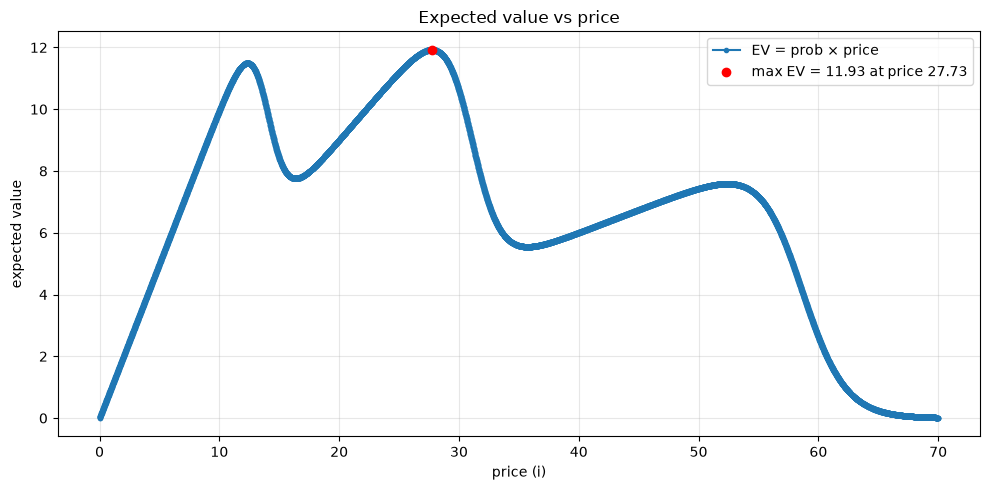

In [3]:
import matplotlib.pyplot as plt

prices = [row[0] for row in data]
evs    = [row[2] for row in data]

best_i  = prices[evs.index(max(evs))]
best_ev = max(evs)

plt.figure(figsize=(10, 5))
plt.plot(prices, evs, marker="o", markersize=3, label="EV = prob × price")
plt.scatter([best_i], [best_ev], color="red", zorder=5,
            label=f"max EV = {best_ev:.2f} at price {best_i}")
plt.xlabel("price (i)")
plt.ylabel("expected value")
plt.title("Expected value vs price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()